# One-Hidden-Layer Learners with Skip Connections on Two-Layer Recurring Tasks

**Question:** how well does a learner with one hidden layer and skip connections do on the problem from 02?

**Teacher.** 21 independent ±1 inputs. Ten lower LTUs are shared by both tasks; each fires when its ±1-weighted input sum exceeds 2, about a third of the time. Each task has its own ten upper LTUs, reading the lower units with ±1 weights and thresholded to fire about 30% of the time, and its own ±1 weights to the same ten outputs. No task ID is given. Targets have Gaussian noise with standard deviation 1, so the RMSE floor is 1.

**Learners.** 21 inputs → 45 LTUs → 10 linear outputs, and the outputs also read the inputs directly, so every unit reads every unit in the layers before it. As many hidden units as 02 (15 + 30). As in 02, hidden units are standardized, h = (b − m) / √max(m(1 − m), 0.01), where m is a running firing rate (rate 0.001), and the backward pass through standardization subtracts running means of the arriving error g and of g h (rate 0.001). LTUs use a sigmoid surrogate derivative. Biases are weights on a constant input. Hidden weights start with fan-in initialization (uniform ±√(3 / 21)) and the readout, including the skip weights, at zero, for both methods.
- **SGD:** one step size for both layers. Sweep 2⁻¹⁰ … 2⁻⁴.
- **Autostep:** `squared_inputs`, meta step 0.02, initial step 2⁻⁸ (settings from 02); no sweep.

**Schedule.** 1.5M steps, switching tasks every 10k steps, starting with task 0. Both methods see the same inputs and noise for a given seed. Five seeds.

Curves show online RMSE (each prediction is made before its update), averaged over 1k-step windows, then over seeds; the first point is step 1.

In [1]:
from functools import partial
from time import perf_counter

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

# Problem
N_INPUTS, N_LOWER, N_UPPER, N_OUTPUTS, N_TASKS = 21, 10, 10, 10, 2
NOISE = 1.

# Learners
WIDTH = 45
EMA_RATE, VAR_FLOOR = 1e-3, .01
INIT_RATE, META_RATE = 2**-8, .02  # Autostep
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')
SGD_EXPONENTS = tuple(range(-10, -3))

# Schedule
PERIOD, STEPS, WINDOW = 10_000, 1_500_000, 1000
N_SEEDS = 5

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

## Task

In [2]:
CALIBRATION = jax.random.rademacher(jax.random.PRNGKey(0), (10_000, N_INPUTS), dtype=jnp.float32)


def init_teacher(key):
    lower_key, upper_key, out_key = jax.random.split(key, 3)
    lower = jax.random.rademacher(lower_key, (N_LOWER, N_INPUTS), dtype=jnp.float32)
    upper = jax.random.rademacher(upper_key, (N_TASKS, N_UPPER, N_LOWER), dtype=jnp.float32)
    out = jax.random.rademacher(out_key, (N_TASKS, N_OUTPUTS, N_UPPER), dtype=jnp.float32)
    # Threshold each upper unit at the half-integer that makes it fire closest to 30% of the time.
    sums = jnp.einsum('tul,nl->tun', upper, (CALIBRATION @ lower.T > 2).astype(jnp.float32))
    candidates = jnp.arange(-N_LOWER, N_LOWER) + .5
    rates = (sums[..., None] > candidates).mean(2)
    return lower, upper, candidates[jnp.abs(rates - .3).argmin(-1)], out


def target(teacher, task, x):
    lower, upper, thresholds, out = teacher
    return out[task] @ (upper[task] @ (lower @ x > 2).astype(jnp.float32) > thresholds[task]).astype(jnp.float32)

## Learners

In [3]:
def init_learner(key):
    bound = np.sqrt(3 / N_INPUTS)
    hidden = jax.random.uniform(key, (WIDTH, N_INPUTS + 1), minval=-bound, maxval=bound).at[:, -1].set(0.)
    return (hidden, jnp.zeros((N_OUTPUTS, WIDTH + N_INPUTS + 1))), jnp.full(WIDTH, .5), jnp.zeros((2, WIDTH))  # weights, firing rates, error traces


def learn(learner, x, y):
    """Prediction error, the gradients and inputs of both layers, and the updated firing rates and error traces."""
    (hidden, readout), mean, (error_mean, error_h_mean) = learner
    source = jnp.append(x, 1.)
    z = hidden @ source
    bits = (z > 0).astype(jnp.float32)
    mean = mean + EMA_RATE * (bits - mean)
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    top = jnp.concatenate([h, source])  # hidden units, then the skip connections from the inputs and bias
    error = readout @ top - y
    g = readout[:, :WIDTH].T @ error  # error arriving at h
    corrected = (g - error_mean - jnp.where(variance > VAR_FLOOR, h * error_h_mean, 0.)) / scale
    surrogate = jax.nn.sigmoid(z) * (1 - jax.nn.sigmoid(z))
    grads = ((corrected * surrogate)[:, None] * source, error[:, None] * top)
    traces = jnp.stack([error_mean + EMA_RATE * (g - error_mean), error_h_mean + EMA_RATE * (g * h - error_h_mean)])
    return error, grads, (source, top), mean, traces


def sgd_step(state, x, y):
    (weights, mean, traces), rate = state
    error, grads, _, mean, traces = learn((weights, mean, traces), x, y)
    weights = tuple(w - rate * g for w, g in zip(weights, grads))
    return ((weights, mean, traces), rate), jnp.mean(error ** 2)


def autostep_step(state, x, y):
    (weights, mean, traces), opt = state
    error, grads, sources, mean, traces = learn((weights, mean, traces), x, y)
    updates, opt = OPTIMIZER.update((grads, None, tuple(s[None] for s in sources)), opt, weights)
    return ((jax.tree.map(jnp.add, weights, updates), mean, traces), opt), jnp.mean(error ** 2)

## Experiment

Runtime: 53.7s


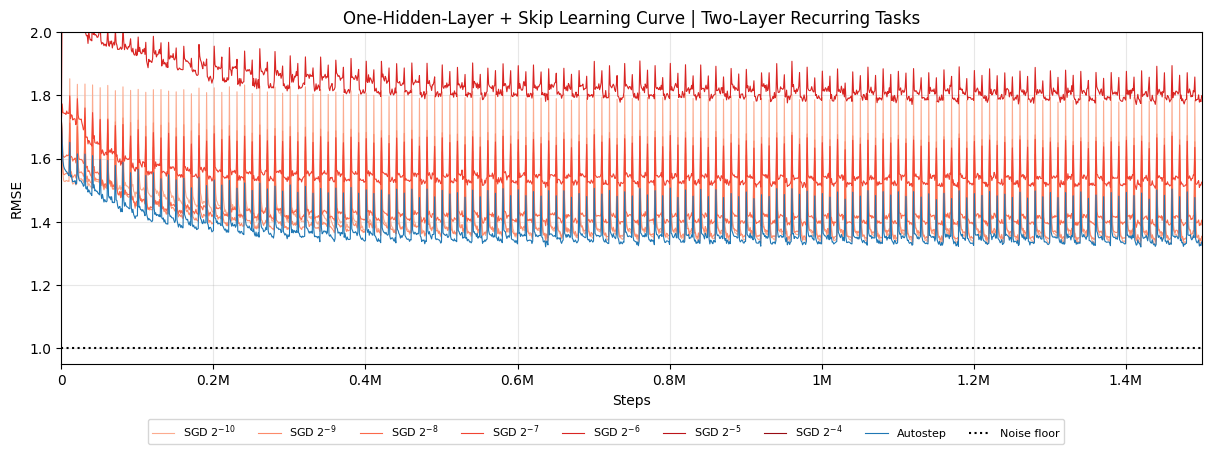

In [4]:
TASKS = np.arange(STEPS // WINDOW) * WINDOW // PERIOD % 2


def run(step, state, key, teacher):
    """Online RMSE of the first example, then of each window."""
    def window(carry, task):
        def sample(carry, _):
            state, key = carry
            key, x_key, noise_key = jax.random.split(key, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, task, x) + NOISE * jax.random.normal(noise_key, (N_OUTPUTS,))
            state, squared_error = step(state, x, y)
            return (state, key), squared_error
        carry, squared_error = jax.lax.scan(sample, carry, None, length=WINDOW)
        return carry, (squared_error.mean(), squared_error[0])
    _, (mse, first) = jax.lax.scan(window, (state, key), TASKS)
    return jnp.sqrt(jnp.concatenate([first[:1], mse]))


teacher_keys, learner_keys, data_keys = jax.random.split(jax.random.PRNGKey(0), (3, N_SEEDS))  # same teachers and data as 02
teachers = jax.vmap(init_teacher)(teacher_keys)
learners = jax.vmap(init_learner)(learner_keys)
run_seeds = lambda step, states: jax.vmap(partial(run, step))(states, data_keys, teachers)

started = perf_counter()
rates = 2. ** np.array(SGD_EXPONENTS)
sgd = np.asarray(jax.jit(jax.vmap(lambda rate: run_seeds(sgd_step, (learners, jnp.full(N_SEEDS, rate)))))(rates))
autostep = np.asarray(jax.jit(partial(run_seeds, autostep_step))((learners, jax.vmap(OPTIMIZER.init)(learners[0]))))
print(f'Runtime: {perf_counter() - started:.1f}s')

steps = np.concatenate([[1], np.arange(1, autostep.shape[-1]) * WINDOW])
fig, ax = plt.subplots(figsize=(12, 4.4), layout='constrained')
for curve, p, color in zip(sgd, SGD_EXPONENTS, plt.cm.Reds(np.linspace(.3, .9, len(rates)))):
    ax.plot(steps, curve.mean(0), label=f'SGD $2^{{{p}}}$', color=color, lw=.8)
ax.plot(steps, autostep.mean(0), label='Autostep', color='tab:blue', lw=.8)
ax.axhline(1., color='black', ls=':', label='Noise floor')
ax.set(xlim=(0, STEPS), ylim=(.95, 2.), xlabel='Steps', ylabel='RMSE', title='One-Hidden-Layer + Skip Learning Curve | Two-Layer Recurring Tasks')  # diverging step sizes leave the plot
ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1e6:g}M' if v else '0')
ax.grid(True, alpha=.3)
fig.legend(fontsize=8, ncol=len(rates) + 2, loc='outside lower center')
plt.show()